Step 7 Designed Treshold
  Target PFA |    T / sigma |   Treshold T
__________________________________________
1.000000e-02 |       3.0349 |       3.0349
1.000000e-03 |       3.7169 |       3.7169
1.000000e-04 |       4.2919 |       4.2919
1.000000e-06 |       5.2565 |       5.2565
Monte Carlo Verification
Number of Trails: 500000
False alarms: 512
Simulated PFA: 0.001024
Theoretical PFA: 0.001000
Standard Error: 4.523166e-05
             -1.00 |       0.8913 |    1.672125e-04 |                           0.17x
              0.00 |       1.0000 |    1.000082e-03 |                           1.00x
              1.00 |       1.1220 |    4.140414e-03 |                           4.14x
              2.00 |       1.2589 |    1.279825e-02 |                          12.80x
              3.00 |       1.4125 |    3.136579e-02 |                          31.37x


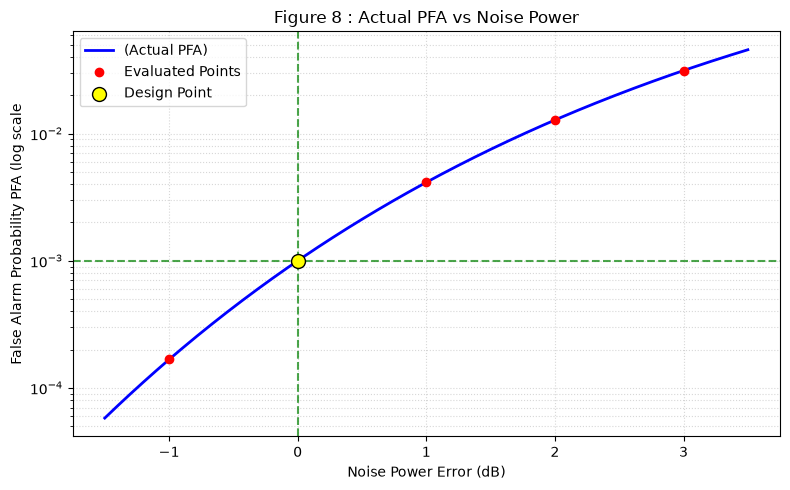

In [12]:
import numpy as np 
import matplotlib.pyplot as plt

SEED = 629064958
rng = np.random.default_rng(SEED)

rng_step7 = rng.spawn(1)[0] 

sigma = 1 
pfa_targets = [1e-2, 1e-3, 1e-4, 1e-6]

print("Step 7 Designed Treshold") 
print(f"{'Target PFA':>12} | {'T / sigma' :>12} | {'Treshold T':>12}")
print("_" * 42)

thresholds = {} 
for pfa in pfa_targets: 
    t_over_sigma = np.sqrt(-2 * np.log(pfa))
    t_value = sigma *  t_over_sigma
    thresholds[pfa] = t_value
    print(f"{pfa:>12e} | {t_over_sigma:>12.4f} | {t_value:>12.4f}")

print("Monte Carlo Verification") 
N_trials = 500000
T_design = thresholds[1e-3]

noise = rng_step7.rayleigh(scale = sigma, size = N_trials)
false_alarms = np.sum(noise > T_design)
pfa_simulated = false_alarms / N_trials 

std_error = np.sqrt(pfa_simulated * (1 - pfa_simulated) / N_trials)
print(f"Number of Trails: {N_trials}")
print(f"False alarms: {false_alarms}")
print(f"Simulated PFA: {pfa_simulated:.6f}")
print(f"Theoretical PFA: {1e-3:.6f}")
print(f"Standard Error: {std_error:.6e}") 


delta_db_list = [-1, 0, 1, 2, 3]
T_design = 3.7169
sigma_assumed = 1.0

actual_pfa_list = []
for delta_db in delta_db_list:
    power_ratio = 10.0 ** (delta_db / 10.0)
    sigma_true = sigma * np.sqrt(power_ratio)
    actual_pfa = np.exp(-(T_design ** 2) / (2.0 * (sigma_true ** 2)))
    actual_pfa_list.append(actual_pfa)
    ratio = actual_pfa / 1e-3
    print(f"{delta_db:>18.2f} | {sigma_true:>12.4f} | {actual_pfa:>15.6e} | {ratio:>30.2f}x")

db_smooth = np.linspace(-1.5, 3.5, 300)
sigma_smooth = sigma * np.sqrt(10 ** (db_smooth / 10))
pfa_smooth = np.exp(-(T_design ** 2) / (2.0 * (sigma_smooth** 2))) 

plt.figure(figsize=(8,5))
plt.plot(db_smooth, pfa_smooth, label = "(Actual PFA)", color = "blue", linewidth = 2)
plt.scatter(delta_db_list, actual_pfa_list, color= "red", zorder = 5, label= "Evaluated Points")

plt.scatter([0], [1e-3], color = "yellow", edgecolor = "black", s=100, zorder= 6, label = "Design Point") 
plt.axhline(1e-3, color = "green", linestyle= "--" , alpha = .7)
plt.axvline(0, color = "green", linestyle= "--" , alpha = .7)

plt.yscale("log")
plt.xlabel("Noise Power Error (dB)")
plt.ylabel("False Alarm Probability PFA (log scale")
plt.title("Figure 8 : Actual PFA vs Noise Power")
plt.grid(True, which = "both", linestyle = ":", alpha = .5)
plt.legend(loc = "upper left")
plt.tight_layout()
plt.show()